# Tumor core / margin / dist analysis with cell-type labels

`skny.pp.calculate_region` is a variant of `skny.pp.calculate_distance` for **cell-level** data whose cells are already annotated
(e.g. a scanpy object). The tumor is defined by a **cell label** (here `"Tumor"`) instead of marker gene expression on a grid,
and every cell is assigned to one of three regions:

| region | definition |
|---|---|
| `core` | bins within 15 µm (`nest_radius`) of a tumor cell = the area actually occupied by tumor cells. No closing / hole filling, so stroma enclosed by tumor is **not** core. Isolated components with fewer than 5 tumor cells (`min_nest_cells`) are discarded. |
| `margin` | tissue outside the core and within 100 µm (`margin`) of the core boundary (peri-tumoral stroma) |
| `dist` | tissue farther than 100 µm from the core boundary |
| `outside` | outside the tissue mask (built from the density of *all* cells), never counted |

`skny.pp.region_density` then gives the density (cells / mm²) of any cell group (e.g. immune cell types) in each region.

## 1. Loading library

In [1]:
# import library
import numpy as np
import pandas as pd
import warnings; warnings.filterwarnings("ignore")
import scanpy as sc
import skny as sk
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
print("skny", sk.__version__)

skny 0.3.0


## 2. Reading Xenium data

Download the Feature-cell Matrix (HDF5) and the Cell summary file (CSV) from the Xenium breast cancer tumor microenvironment dataset
(the same files as in the tutorial *Tumor contour with Xenium data*).

You need these 2 files in a new folder `tutorial_data/xenium_data` in the same path as your notebook.

* Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5
* Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz

In [2]:
# !mkdir tutorial_data
# !mkdir tutorial_data/xenium_data
# !wget -P tutorial_data/xenium_data/ https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5
# !wget -P tutorial_data/xenium_data/ https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz

In [3]:
# Load Xenium data using scanpy: cells x genes matrix + cell centroids (micrometres)
adata = sc.read_10x_h5("tutorial_data/xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5")
adata.var_names_make_unique()
cells = pd.read_csv("tutorial_data/xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz", index_col="cell_id")
cells.index = cells.index.astype(str)                                         # match the cell ids of the matrix
adata.obs = adata.obs.join(cells[["x_centroid", "y_centroid", "transcript_counts", "cell_area"]])
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].to_numpy()   # coordinates in um
adata

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'cell_area'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'

## 3. Cell type annotation

`calculate_region` needs a cell label. Here we obtain one quickly with the standard scanpy workflow
(QC → normalisation → PCA → neighbours → Leiden) and assign each cluster to the cell type whose marker score is highest.
Any other annotation (manual, reference-based, from another tool) works as well.

In [4]:
# QC and clustering
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=10)
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata); sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, directed=False, random_state=0)
adata.obs["leiden"].value_counts().head(10)

leiden
3    36698
6    30120
5    22209
4    15394
0    15265
2    14435
7    12479
1     8446
9     4791
8     4163
Name: count, dtype: int64

In [5]:
# marker-based annotation of the Leiden clusters
markers = {
    "Tumor":         ["EPCAM", "KRT8", "ERBB2", "CEACAM6", "CDH1"],
    "Myoepithelial": ["KRT15", "KRT5", "ACTA2", "MYH11"],
    "T cell":        ["CD3E", "CD3D", "CD2", "IL7R"],
    "B cell":        ["MS4A1", "BANK1", "CD19"],
    "Plasma cell":   ["MZB1", "IGHG1", "JCHAIN"],
    "Macrophage":    ["CD68", "CD163", "MRC1", "C1QA"],
    "Fibroblast":    ["PDGFRB", "LUM", "FBLN1", "SFRP4"],
    "Endothelial":   ["PECAM1", "VWF", "CLDN5"],
    "Mast cell":     ["KIT", "CPA3", "MS4A2"],
    "Adipocyte":     ["ADIPOQ", "LPL"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
for ct, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=f"score_{ct}")
score_cols = [f"score_{ct}" for ct in markers]
cl_scores = adata.obs.groupby("leiden", observed=True)[score_cols].mean()
cl_scores = (cl_scores - cl_scores.mean()) / cl_scores.std()          # z-score per cell type across clusters
cluster_to_celltype = cl_scores.idxmax(axis=1).str.replace("score_", "")
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_celltype).astype("category")
adata.obs["cell_type"].value_counts()

cell_type
Tumor            66398
T cell           30120
Fibroblast       22209
Macrophage       15394
Endothelial      12479
Myoepithelial     8446
Plasma cell       4791
B cell            4163
Name: count, dtype: int64

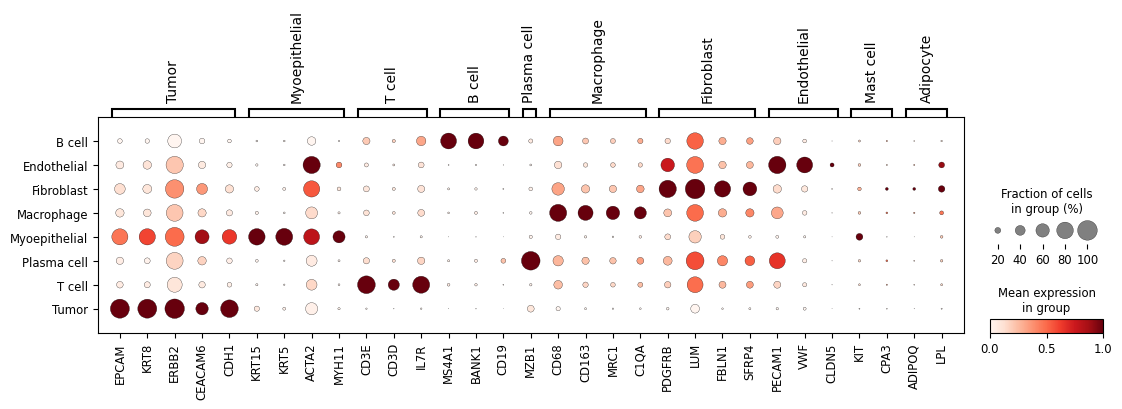

In [6]:
# check the annotation with a marker dot plot
sc.pl.dotplot(adata, markers, groupby="cell_type", standard_scale="var")

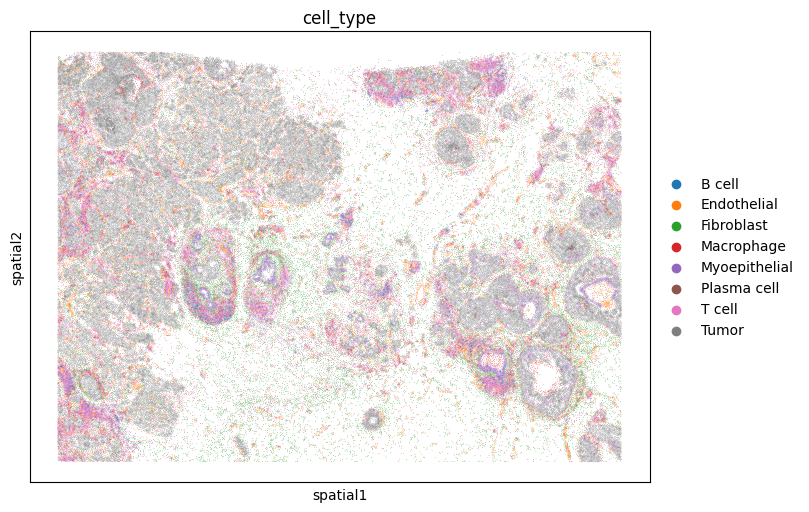

In [7]:
# cell types on space
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(adata, basis="spatial", color="cell_type", size=1, ax=ax, show=False)
ax.set_aspect("equal"); ax.invert_yaxis()
plt.show()

## 4. Tumor core / margin / dist

`calculate_region` assigns every cell to a region. `ref_label` is the label (or list of labels) that defines the tumor;
coordinates are taken from `adata.obsm["spatial"]` (micrometres) or from two `obs` columns given with `coord_keys`.
With several sections in one object, pass `sample_key` and the regions are computed per sample.

In [8]:
# contour-free region assignment from the cell label
sk.pp.calculate_region(adata, "Tumor", label_key="cell_type")
adata.obs["region"].value_counts()

[skny] sample: core=13.141 mm2, margin=11.364 mm2, dist=17.572 mm2


region
core            86620
margin          43410
dist            33925
outside            45
not_computed        0
Name: count, dtype: int64

The region map, areas and the parameters are stored in `adata.uns["region"]`; the distance of every cell to the nearest tumor cell is in `adata.obs["region_dist_um"]`.

In [9]:
# region areas (mm2) and parameters
print(adata.uns["region"]["maps"]["sample"]["area_mm2"])
adata.uns["region"]["params"]

{'core': 13.1412, 'margin': 11.3642, 'dist': 17.5724}


{'ref_label': ['Tumor'],
 'label_key': 'cell_type',
 'sample_key': None,
 'bin_um': 10.0,
 'nest_radius': 15.0,
 'margin': 100.0,
 'min_nest_cells': 5,
 'min_ref_cells': 20,
 'tissue_smooth': 60.0,
 'tissue_min_density': 250.0,
 'min_tissue_area': 0.1,
 'core_only': False,
 'margin_from': 'nest'}

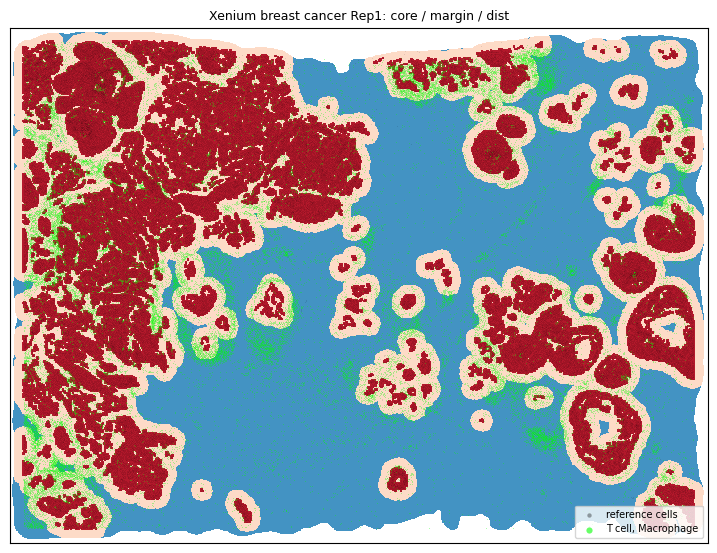

In [10]:
# plot the regions: red = core, light red = margin, blue = dist, white = outside the tissue mask
ax = sk.pl.region_map(adata, highlight=["T cell", "Macrophage"], s=0.2, figsize=(9, 7), title="Xenium breast cancer Rep1: core / margin / dist")

Tumor nests (core) are drawn directly from the tumor cells, so ducts of DCIS and invasive nests both appear as core and the stroma between them is margin (or dist when it is farther than 100 µm from any nest).

## 5. Cell density per region

`region_density` counts the cells of each group in each region and divides by the region area (cells / mm²). Here we use the cell types themselves; in a real study this would typically be immune subtypes from a sub-clustering.

In [11]:
# density (cells / mm2) of each cell type per region
df = sk.pp.region_density(adata, "cell_type")
df.pivot(index="group", columns="region", values="density").loc[:, ["core", "margin", "dist"]].round(1)

region,core,margin,dist
group,,,
B cell,8.4,143.8,137.7
Endothelial,222.4,530.5,200.4
Fibroblast,232.7,782.4,582.3
Macrophage,253.8,613.4,289.3
Myoepithelial,492.3,118.9,35.6
Plasma cell,22.3,237.5,102.4
T cell,321.3,1382.4,579.4
Tumor,5038.3,11.0,3.6
_all_cells,6591.5,3819.9,1930.6


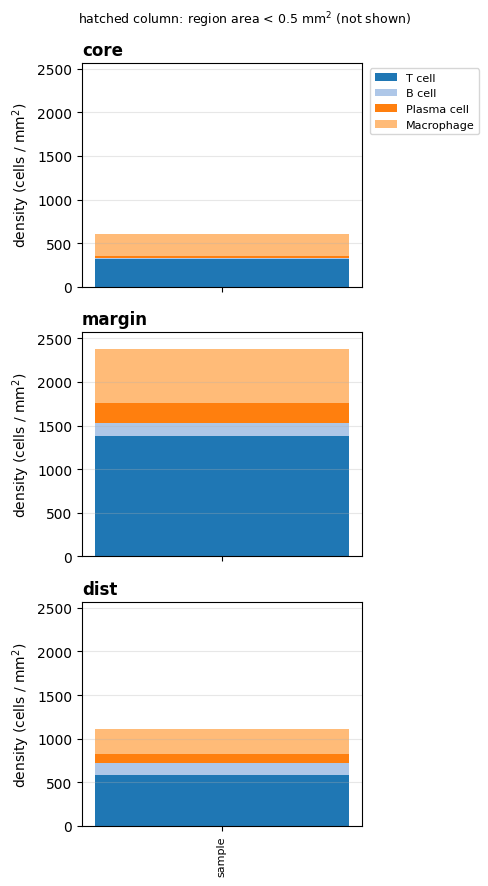

In [12]:
# stacked bars per sample (one sample here); regions smaller than min_area_mm2 would be hatched
fig, axes = sk.pl.region_density_plot(df, groups=["T cell", "B cell", "Plasma cell", "Macrophage"], min_area_mm2=0.5, figsize=(5, 9))

All immune populations peak in the peri-tumoral margin. Inside the tumor core, T cells and macrophages are still present while B cells and plasma cells are almost absent.

## 6. Distance profile

Because the distance to the nearest tumor cell is stored per cell, a continuous profile is also available, similar to the
equidistant bands of `calculate_distance`.

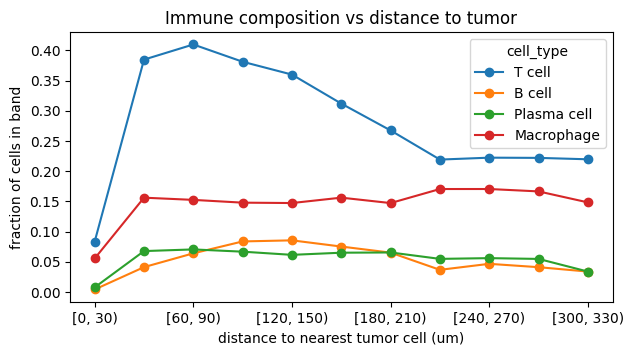

In [13]:
# fraction of immune cells as a function of the distance to the nearest tumor cell (30 um bands, tissue only)
sub = adata.obs[adata.obs["region"].isin(["core", "margin", "dist"])].copy()
sub["band"] = pd.cut(sub["region_dist_um"], bins=np.arange(0, 331, 30), right=False)
prof = sub.groupby("band", observed=True)["cell_type"].value_counts(normalize=True).unstack().fillna(0)
prof[["T cell", "B cell", "Plasma cell", "Macrophage"]].plot(figsize=(7, 3.5), marker="o")
plt.ylabel("fraction of cells in band"); plt.xlabel("distance to nearest tumor cell (um)"); plt.title("Immune composition vs distance to tumor")
plt.show()

## Parameters

| parameter | default | meaning |
|---|---|---|
| `bin_um` | 10 | grid size (µm) |
| `nest_radius` | 15 | core = bins within this distance of a reference cell |
| `margin` | 100 | width of the margin band outside the core (µm) |
| `min_nest_cells` | 5 | isolated core components with fewer reference cells are discarded |
| `min_ref_cells` | 20 | samples with fewer reference cells are skipped (`not_computed`) |
| `tissue_smooth` / `tissue_min_density` / `min_tissue_area` | 60 µm / 250 cells per mm² / 0.1 mm² | tissue mask from the density of all cells |
| `core_only` | False | define only the core (e.g. for a rare tumor subpopulation compared with the main tumor core) |
| `margin_from` | `"nest"` | `"reference"` measures the margin from any reference cell (legacy: isolated reference cells keep a margin halo) |
| `key_added` | `"region"` | keep several definitions side by side (`region_density` / `region_map` take `region_key`) |